# 병합 충돌 해결

**이 노트북에서 할 일**

1. 02절처럼 임시 폴더에 팀 원격 저장소와 작성자·리뷰어 저장소를 만듭니다.
2. 두 사람이 서로 다른 파일을 고친 뒤, 올리기 거절에서 병합까지의 순서를 봅니다.
3. 두 사람이 같은 줄을 고쳐 병합이 멈추면, 팀의 출고 기준으로 한 줄을 정해 병합을 마칩니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 모델 호출은 0번이고 비용은 들지 않습니다.
실행 시간은 1분 이내입니다. 02절에서 쓴 Git이 필요합니다.

실습 폴더 `labs/part1/ch03-git-github`에서 `uv sync --locked`로 만든 `.venv`를 커널로 고릅니다.
첫 셀부터 순서대로 실행합니다. GitHub 계정과 네트워크는 쓰지 않습니다.

## 오늘 볼 그림

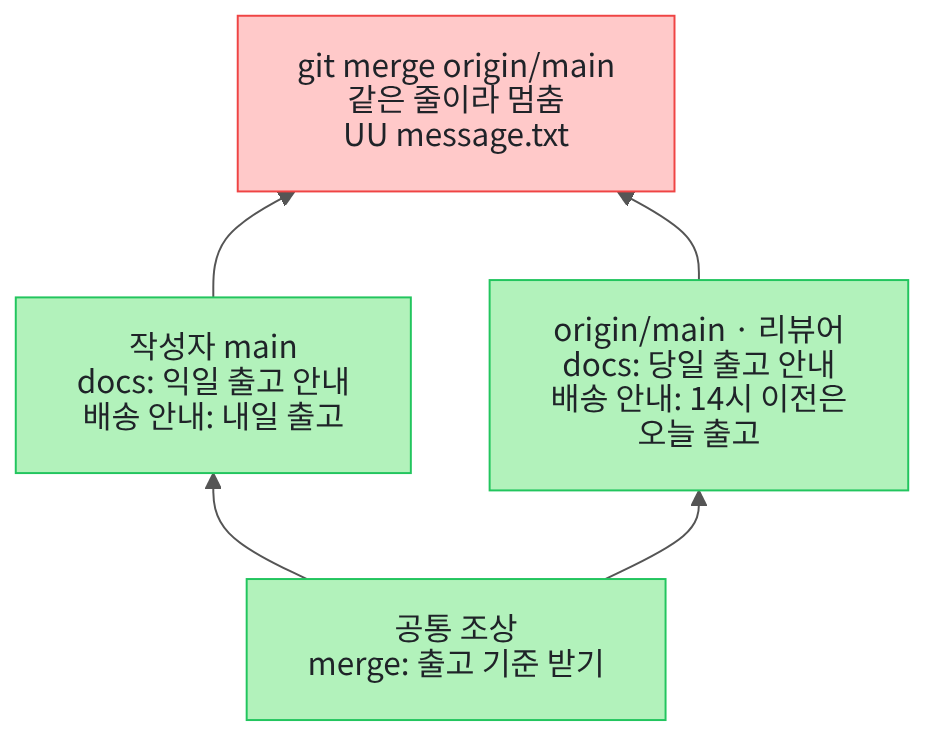

아래에서 위로 읽습니다. 맨 아래 커밋에서 두 사람의 줄기가 갈라지고, 두 커밋이 같은 줄을 서로 다르게 고쳤습니다.
맨 위 빨간 상자는 두 줄기를 합치려던 병합이 멈춘 자리입니다. 이 노트북은 이 상태를 직접 만들고 마무리합니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 02절처럼 빈 임시 폴더를 만들고 그 폴더로 작업 위치를 옮깁니다.
그 안에 원격 저장소 하나와 두 사람의 저장소를 만듭니다. 폴더 이름의 앞머리만 `ch03-03-`으로 바꿨습니다.

In [1]:
# 저장소 세 개를 담을 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch03-03-")
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.

## 2. git 명령 함수 다시 만들기

02절의 `run_git()` 함수를 같은 모양으로 다시 정의합니다. 노트북을 새로 열면 앞 노트북에서 만든 함수는 남아 있지 않습니다.
두 번째 매개변수 `folder`는 명령을 실행할 폴더이고, 기본값 `"."`은 현재 작업 폴더입니다.

이 함수에는 `check=True` 인자가 없습니다. 그래서 git 명령이 실패해도 셀은 멈추지 않고 `종료 코드: 1` 같은 줄을 보여 줍니다.
이 절에서는 실패한 명령의 출력과 이 줄을 여러 번 읽습니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [2]:
# git 명령을 폴더 하나에서 실행하고, 폴더 이름과 명령, 출력을 함께 보여 주는 함수
import shlex
import subprocess


def run_git(command: str, folder: str = "."):
    full_command = "git " + command
    # split()은 따옴표로 묶은 메시지를 공백이 있어도 한 낱말로 둡니다
    arguments = shlex.split(full_command)
    # cwd 인자에 적은 폴더에서 명령을 실행하고, 글자는 UTF-8 규칙으로 읽습니다
    result = subprocess.run(arguments, capture_output=True, encoding="utf-8", cwd=folder)
    print(folder, "$", full_command)
    print(result.stdout + result.stderr)
    # 종료 코드가 0이 아닐 때만 숫자를 보여 줍니다
    if result.returncode != 0:
        print("종료 코드:", result.returncode)

**결과 읽기** — 예상대로 출력이 없습니다. 함수를 새로 정의하기만 했습니다.

## 3. 팀 원격 저장소와 작성자 저장소 만들기

02절과 같은 순서로 준비합니다. 원격 저장소 `team.git`을 bare 저장소로 만들고, 작성자가 `author` 폴더로 복제합니다.
작성자 정보도 02절과 같은 `Ch3 Student`를 이 저장소에만 적습니다.

실행 전에 예상합니다. 빈 저장소를 복제했다는 경고가 한 번 나오고, 종료 코드 줄은 없을 것입니다.

In [3]:
# 팀 원격 저장소를 만들고, 작성자가 복제한 저장소에 이름과 전자우편 주소를 적습니다
run_git("init --bare -b main team.git")
run_git("clone team.git author")
run_git('config user.name "Ch3 Student"', "author")
run_git("config user.email student@example.com", "author")

. $ git init --bare -b main team.git
Initialized empty Git repository in [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team.git/

. $ git clone team.git author
Cloning into 'author'...
done.

author $ git config user.name "Ch3 Student"

author $ git config user.email student@example.com



**결과 읽기** — 줄 `Initialized empty Git repository`로 원격 저장소가 생긴 것을 확인합니다.
경고 `You appear to have cloned an empty repository`는 02절에서 본 것과 같은 안내입니다.
종료 코드 줄이 없으므로 네 명령 모두 성공했습니다.

## 4. 첫 커밋을 올리고 리뷰어도 복제하기

작성자가 배송 안내 파일 `message.txt`를 만들어 main의 첫 커밋으로 올립니다. 파일에는 `배송 안내: 준비 중` 한 줄만 적습니다.
이 한 줄이 뒤에서 두 사람이 함께 고칠 줄입니다.
메시지 앞머리 `docs:`는 문서 파일을 고친 커밋에 붙이는 이 교재의 팀 관례입니다.

실행 전에 예상합니다. 02절처럼 첫 커밋 표시와 새 브랜치 표시가 나올 것입니다.

In [4]:
# 작성자가 배송 안내 파일을 만들어 첫 커밋으로 기록하고 원격에 올립니다
with open("author/message.txt", "w", encoding="utf-8") as file:
    file.write("배송 안내: 준비 중\n")
run_git("add message.txt", "author")
run_git('commit -m "docs: 배송 안내 시작"', "author")
run_git("push -u origin main", "author")

author $ git add message.txt

author $ git commit -m "docs: 배송 안내 시작"
[main (root-commit) 7fb1b5f] docs: 배송 안내 시작
 1 file changed, 1 insertion(+)
 create mode 100644 message.txt

author $ git push -u origin main
Branch 'main' set up to track remote branch 'main' from 'origin'.
To [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team.git
 * [new branch]      main -> main



**결과 읽기** — 표시 `main (root-commit)`은 main 브랜치의 첫 커밋이라는 뜻입니다.
올리기 출력의 `[new branch]`로 원격 저장소에도 main이 생긴 것을 확인합니다.

리뷰어도 원격 저장소를 복제합니다. 02절의 리뷰어 `Ch3 Reviewer`가 이번에는 팀원으로서 파일을 직접 고칩니다.
폴더 이름과 작성자 정보는 02절과 같게 둡니다.

실행 전에 예상합니다. 원격에 커밋이 있으니 빈 저장소 경고 없이 복제될 것입니다.

In [5]:
# 리뷰어가 원격 저장소를 복제하고, 리뷰어 저장소에만 이름과 전자우편 주소를 적습니다
run_git("clone team.git reviewer")
run_git('config user.name "Ch3 Reviewer"', "reviewer")
run_git("config user.email reviewer@example.com", "reviewer")

. $ git clone team.git reviewer
Cloning into 'reviewer'...
done.

reviewer $ git config user.name "Ch3 Reviewer"

reviewer $ git config user.email reviewer@example.com



**결과 읽기** — 복제 출력은 `Cloning into 'reviewer'...`와 `done.`뿐이고 경고가 없습니다.
이제 두 사람의 main은 같은 첫 커밋에서 출발합니다.

## 5. 두 사람이 서로 다른 파일을 고치기

이제 두 사람이 서로의 작업을 모르는 채로 각자 커밋합니다. 먼저 리뷰어가 출고 기준 파일 `policy.txt`를 더해 원격에 올립니다.
이 파일은 결제 시각에 따라 출고일이 달라진다는 팀의 기준입니다.

리뷰어의 main은 02절에서 본 것처럼 복제할 때 이미 원격 main과 짝이 됐습니다. 그래서 원격과 브랜치 이름 없이 `git push`만 적습니다.
실행 전에 예상합니다. 원격 main이 새 커밋으로 옮겨 갔다는 줄이 나올 것입니다.

In [6]:
# 리뷰어가 출고 기준 파일을 커밋하고 원격에 올립니다
policy_text = """14시 이전 결제: 오늘 출고
14시 이후 결제: 내일 출고
"""
with open("reviewer/policy.txt", "w", encoding="utf-8") as file:
    file.write(policy_text)
run_git("add policy.txt", "reviewer")
run_git('commit -m "docs: 출고 기준 기록"', "reviewer")
run_git("push", "reviewer")

reviewer $ git add policy.txt

reviewer $ git commit -m "docs: 출고 기준 기록"
[main dd13de0] docs: 출고 기준 기록
 1 file changed, 2 insertions(+)
 create mode 100644 policy.txt

reviewer $ git push
To [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team.git
   7fb1b5f..dd13de0  main -> main



**결과 읽기** — 커밋 요약 줄은 `1 file changed, 2 insertions(+)`입니다.
올리기 출력의 `main -> main`은 원격 main이 리뷰어의 새 커밋으로 옮겨 갔다는 뜻입니다.

같은 시간에 작성자는 다른 파일 `contact.txt`에 문의 안내를 적어 커밋합니다. 작성자 저장소는 리뷰어가 방금 올린 커밋을 아직 모릅니다.
커밋한 뒤 02절처럼 `git push`로 올려 봅니다.

실행 전에 예상합니다. 고친 파일은 달라도, 원격 main에 작성자가 모르는 커밋이 있어 올리기가 거절될 것입니다.

In [7]:
# 작성자가 다른 파일에 문의 안내를 커밋하고, 원격에 올려 봅니다
with open("author/contact.txt", "w", encoding="utf-8") as file:
    file.write("문의 안내: 주문 번호와 함께 남겨 주세요\n")
run_git("add contact.txt", "author")
run_git('commit -m "docs: 문의 안내 추가"', "author")
run_git("push", "author")

author $ git add contact.txt

author $ git commit -m "docs: 문의 안내 추가"
[main f50fbd7] docs: 문의 안내 추가
 1 file changed, 1 insertion(+)
 create mode 100644 contact.txt

author $ git push
To [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to '[사용자 폴더]/tmp/ch03-03-z3v2kqjw/team.git'
hint: Updates were rejected because the remote contains work that you do
hint: not have locally. This is usually caused by another repository pushing
hint: to the same ref. You may want to first integrate the remote changes
hint: (e.g., 'git pull ...') before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.

종료 코드: 1


**결과 읽기** — 표시 `! [rejected]`와 `(fetch first)`는 원격 저장소가 올리기를 거절했다는 뜻입니다.
마지막 줄 `종료 코드: 1`로 git 명령이 실패한 것을 확인합니다.

안내 줄 `the remote contains work that you do`는 원격에 내 저장소에 없는 커밋이 있다는 설명입니다.
원격 main을 작성자의 커밋으로 옮기면 리뷰어의 커밋이 main에서 빠집니다. 그래서 파일이 달라도 올리기를 거절했습니다.

## 6. 받아 와서 갈라진 모양 보기

거절 안내는 원격의 변경을 먼저 합친 뒤 다시 올리라고 합니다. 02절처럼 `git fetch`로 원격의 새 커밋을 받아 오고, `git branch -vv`로 짝과 비교합니다.

실행 전에 예상합니다. 02절에서 따로 본 `ahead`와 `behind`가 한 줄에 함께 나올 것입니다.

In [8]:
# 작성자 저장소에서 원격의 새 커밋을 받아 오고, 짝과 비교한 결과를 봅니다
run_git("fetch", "author")
run_git("branch -vv", "author")

author $ git fetch
From [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team
   7fb1b5f..dd13de0  main       -> origin/main

author $ git branch -vv
* main f50fbd7 [origin/main: ahead 1, behind 1] docs: 문의 안내 추가



**결과 읽기** — 목록의 `[origin/main: ahead 1, behind 1]`은 내 main이 짝보다 커밋 1개 앞서고 1개 뒤처졌다는 뜻입니다.
앞선 커밋은 작성자의 `docs: 문의 안내 추가`이고, 뒤처진 커밋은 리뷰어가 올린 커밋입니다.

두 줄기가 첫 커밋에서 갈라져 각자 커밋을 하나씩 더한 모양입니다. 이런 상태를 갈라진 이력이라고 부릅니다.

## 7. 병합하고 다시 올리기

갈라진 두 줄기는 병합으로 합칩니다. 02절에서 리뷰어가 원격 이름을 병합했듯이, 작성자는 `origin/main`을 내 main에 병합합니다.
두 줄기가 이미 갈라져 있으므로 옵션 `--no-ff`가 없어도 병합 커밋이 생깁니다. 옵션 `-m`으로 병합 커밋의 메시지를 적습니다.

실행 전에 예상합니다. 서로 다른 파일을 고쳤으니 자동으로 합쳐지고, 이번에는 올리기가 성공할 것입니다.

In [9]:
# 원격 main을 작성자 main에 병합하고, 병합 커밋을 원격에 올립니다
run_git('merge origin/main -m "merge: 출고 기준 받기"', "author")
run_git("push", "author")

author $ git merge origin/main -m "merge: 출고 기준 받기"
Merge made by the 'ort' strategy.
 policy.txt | 2 ++
 1 file changed, 2 insertions(+)
 create mode 100644 policy.txt

author $ git push
To [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team.git
   dd13de0..5acd7ab  main -> main



**결과 읽기** — 줄 `Merge made by the 'ort' strategy.`는 병합 커밋을 만들었다는 뜻입니다.
요약 줄의 `policy.txt | 2 ++`는 리뷰어가 더한 파일이 작성자 폴더에 들어왔다는 뜻입니다.
올리기 출력에는 `main -> main`이 나오고, 거절 표시와 종료 코드 줄은 없습니다.

## 8. 리뷰어가 git pull로 받기

이번에는 리뷰어 저장소가 원격보다 뒤처졌습니다. 명령 `git pull`은 `git fetch`로 받아 온 뒤 이어서 병합까지 하는 명령입니다.

리뷰어는 받아 온 커밋 뒤로 새로 커밋한 것이 없습니다. 이럴 때 병합은 병합 커밋을 새로 만들지 않고 main 이름만 앞으로 옮깁니다.
이런 병합을 fast-forward 병합이라고 부릅니다. 02절에서는 이름만 봤습니다.

실행 전에 예상합니다. 출력에 fast-forward 표시가 나오고, 작성자가 만든 파일이 리뷰어 폴더에 들어올 것입니다.

In [10]:
# 리뷰어 저장소에서 원격 main을 받아 와 합칩니다
run_git("pull", "reviewer")

reviewer $ git pull
Updating dd13de0..5acd7ab
Fast-forward
 contact.txt | 1 +
 1 file changed, 1 insertion(+)
 create mode 100644 contact.txt
From [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team
   dd13de0..5acd7ab  main       -> origin/main



**결과 읽기** — 줄 `Fast-forward`는 병합 커밋 없이 main 이름만 앞으로 옮겼다는 뜻입니다.
요약 줄의 `contact.txt | 1 +`로 작성자의 파일이 들어온 것을 확인합니다.

아래쪽 `main       -> origin/main` 줄은 앞 단계인 받아 오기의 출력입니다. 함수가 `result.stdout`을 먼저, `result.stderr`를 나중에 출력해서 순서가 바뀌어 보입니다.
이제 세 저장소의 main이 모두 작성자의 병합 커밋을 가리킵니다.

## 9. 값 하나 바꿔 보기 — 같은 줄을 두 사람이 고치기

5번에서는 두 사람이 서로 다른 파일을 고쳤습니다. 이번에는 고치는 자리 하나만 바꿔, 두 사람이 `message.txt`의 같은 줄을 서로 다르게 고칩니다.
나머지 순서는 5~7번과 같습니다.

먼저 리뷰어가 출고 기준의 첫 줄을 보고 안내를 `배송 안내: 14시 이전은 오늘 출고`로 고쳐 올립니다.
실행 전에 예상합니다. 리뷰어는 방금 받아 왔으므로 올리기가 성공할 것입니다.

In [11]:
# 리뷰어가 배송 안내 줄을 고쳐 커밋하고 원격에 올립니다
with open("reviewer/message.txt", "w", encoding="utf-8") as file:
    file.write("배송 안내: 14시 이전은 오늘 출고\n")
run_git("add message.txt", "reviewer")
run_git('commit -m "docs: 당일 출고 안내"', "reviewer")
run_git("push", "reviewer")

reviewer $ git add message.txt

reviewer $ git commit -m "docs: 당일 출고 안내"
[main 9640ab6] docs: 당일 출고 안내
 1 file changed, 1 insertion(+), 1 deletion(-)

reviewer $ git push
To [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team.git
   5acd7ab..9640ab6  main -> main



**결과 읽기** — 커밋 요약 줄 `1 file changed, 1 insertion(+), 1 deletion(-)`은 한 줄을 지우고 새 줄을 넣었다는 뜻입니다.
01절에서 본 것처럼 줄 하나를 고치면 이렇게 셉니다. 올리기 출력의 `main -> main`으로 원격 main이 옮겨 갔습니다.

작성자는 리뷰어의 새 커밋을 모른 채 같은 줄을 `배송 안내: 내일 출고`로 고쳐 커밋합니다.
이번에는 올리기 전에 6번처럼 먼저 받아 와 짝과 비교합니다.

실행 전에 예상합니다. 6번과 똑같이 한 커밋 앞서고 한 커밋 뒤처졌다는 표시가 나올 것입니다.

In [12]:
# 작성자가 같은 줄을 다르게 고쳐 커밋하고, 원격의 새 커밋을 받아 와 짝과 비교합니다
with open("author/message.txt", "w", encoding="utf-8") as file:
    file.write("배송 안내: 내일 출고\n")
run_git("add message.txt", "author")
run_git('commit -m "docs: 익일 출고 안내"', "author")
run_git("fetch", "author")
run_git("branch -vv", "author")

author $ git add message.txt

author $ git commit -m "docs: 익일 출고 안내"
[main e67e006] docs: 익일 출고 안내
 1 file changed, 1 insertion(+), 1 deletion(-)

author $ git fetch
From [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team
   5acd7ab..9640ab6  main       -> origin/main

author $ git branch -vv
* main e67e006 [origin/main: ahead 1, behind 1] docs: 익일 출고 안내



**결과 읽기** — 목록은 6번과 같은 `[origin/main: ahead 1, behind 1]`입니다. 앞선 커밋은 `docs: 익일 출고 안내`입니다.

짝 비교 표시만 봐서는 5번과 무엇이 다른지 알 수 없습니다. 달라진 것은 두 커밋이 고친 자리이고, 그 차이는 병합할 때 드러납니다.

## 10. Before — 같은 줄을 병합하면 멈춥니다

7번과 같은 명령으로 `origin/main`을 병합합니다. 병합은 두 줄기가 갈라지기 전의 마지막 커밋을 기준으로 삼습니다.
이 커밋을 공통 조상(merge base)이라고 부릅니다. 이번 공통 조상은 7번에서 만든 병합 커밋 `merge: 출고 기준 받기`입니다.

병합할 때는 공통 조상과 비교해 두 쪽이 각각 무엇을 바꿨는지 봅니다. 한쪽만 바꾼 줄은 그 변경을 가져옵니다.
두 쪽이 같은 줄을 서로 다르게 바꾸면 어느 쪽을 고를지 정하지 못합니다.
실행 전에 예상합니다. 병합이 멈추고 `종료 코드: 1` 줄이 나올 것입니다.

In [13]:
# Before: 같은 줄을 다르게 고친 원격 main을 작성자 main에 병합합니다
run_git('merge origin/main -m "merge: 당일 출고 안내 받기"', "author")

author $ git merge origin/main -m "merge: 당일 출고 안내 받기"
Auto-merging message.txt
CONFLICT (content): Merge conflict in message.txt
Automatic merge failed; fix conflicts and then commit the result.

종료 코드: 1


**결과 읽기** — 줄 `CONFLICT (content): Merge conflict in message.txt`는 이 파일의 내용에서 병합 충돌이 났다는 뜻입니다.
마지막 줄은 `종료 코드: 1`이고, 7번과 달리 병합 커밋을 만들었다는 줄이 없습니다.

병합 충돌(merge conflict)은 두 쪽의 변경을 자동으로 합치지 못해 병합을 멈춘 상태입니다.
줄 `Automatic merge failed; fix conflicts and then commit the result.`는 충돌을 고친 뒤 결과를 커밋하라는 안내입니다.

병합이 멈춘 동안 저장소 상태를 보고, 해결하지 않은 채로 바로 커밋해 봅니다. 상태 표시 두 칸은 01절에서 배웠습니다.

실행 전에 예상합니다. 해결하지 않은 파일이 있으니 커밋이 거절될 것입니다.

In [14]:
# Before: 멈춘 병합의 상태를 보고, 해결하지 않은 채로 커밋해 봅니다
run_git("status --short", "author")
run_git('commit -m "merge: 충돌 그대로 기록"', "author")

author $ git status --short
UU message.txt

author $ git commit -m "merge: 충돌 그대로 기록"
U	message.txt
error: Committing is not possible because you have unmerged files.
hint: Fix them up in the work tree, and then use 'git add/rm <file>'
hint: as appropriate to mark resolution and make a commit.
fatal: Exiting because of an unresolved conflict.

종료 코드: 128


**결과 읽기** — 상태 표시는 `UU message.txt`입니다. 충돌 중에는 두 칸의 뜻이 01절과 달라집니다.
두 칸 모두 U인 표시는 두 쪽이 모두 고쳐 아직 해결하지 않은 파일이라는 뜻입니다.
커밋은 `error: Committing is not possible because you have unmerged files.`로 거절됐고, 종료 코드는 `128`입니다.

안내 줄 `use 'git add/rm <file>'`은 파일을 고친 뒤 `git add`로 해결했다고 표시하라는 뜻입니다.

충돌이 난 파일을 읽어 봅니다. 병합이 멈추면 두 쪽의 줄이 모두 파일에 적히고, 그 앞뒤와 사이에 충돌 표시가 들어갑니다.
Ch 2 03절의 `in`으로 충돌 표시 `<<<<<<<`가 글 안에 있는지도 확인합니다.

실행 전에 예상합니다. 작성자의 `내일 출고` 줄과 리뷰어의 `오늘 출고` 줄이 함께 보일 것입니다.

In [15]:
# Before: 충돌이 난 배송 안내 파일을 읽고, 충돌 표시가 남아 있는지 확인합니다
with open("author/message.txt", "r", encoding="utf-8") as file:
    message_text = file.read()
print("작성자의 message.txt:")
print(message_text)
print("충돌 표시가 남아 있음:", "<<<<<<<" in message_text)

작성자의 message.txt:
<<<<<<< HEAD
배송 안내: 내일 출고
배송 안내: 14시 이전은 오늘 출고
>>>>>>> origin/main

충돌 표시가 남아 있음: True


**결과 읽기** — 표시 `<<<<<<< HEAD`와 `=======` 사이는 지금 브랜치 쪽인 작성자의 `배송 안내: 내일 출고`입니다.
표시 `=======`과 `>>>>>>> origin/main` 사이는 병합하려는 쪽인 리뷰어의 `배송 안내: 14시 이전은 오늘 출고`입니다.
마지막 줄 `충돌 표시가 남아 있음: True`로 표시가 파일에 들어 있음을 확인합니다.

표시 줄은 사람이 지워야 합니다. 그리고 두 줄 중 무엇을 남길지도 사람이 정해야 합니다.

## 11. After — 출고 기준으로 한 줄을 정하고 병합 마치기

충돌 표시를 지우는 것만으로는 해결이 끝나지 않습니다. 남길 줄을 고르기 전에 두 줄을 팀의 기준과 비교합니다.
이 저장소의 기준은 5번에서 리뷰어가 올리고 7번에서 작성자 폴더에 들어온 `policy.txt`입니다.

작성자의 줄 「내일 출고」는 14시 이전 결제에 맞지 않습니다. 리뷰어의 줄은 14시 이후 결제를 말하지 않습니다.
그래서 기준의 두 조건을 모두 담은 새 줄로 파일 전체를 다시 쓰고, `git add`로 해결했다고 표시합니다.
실행 전에 예상합니다. 상태 표시가 `UU`에서 색인에 올린 변경 표시로 바뀔 것입니다.

In [16]:
# After: 출고 기준을 읽고, 두 조건을 모두 담은 줄로 배송 안내 파일을 다시 씁니다
with open("author/policy.txt", "r", encoding="utf-8") as file:
    policy_text = file.read()
print("출고 기준 policy.txt:")
print(policy_text)
resolved_line = "배송 안내: 14시 이전 결제는 오늘 출고, 14시 이후 결제는 내일 출고\n"
with open("author/message.txt", "w", encoding="utf-8") as file:
    file.write(resolved_line)
run_git("add message.txt", "author")
run_git("status --short", "author")

출고 기준 policy.txt:
14시 이전 결제: 오늘 출고
14시 이후 결제: 내일 출고

author $ git add message.txt

author $ git status --short
M  message.txt



**결과 읽기** — 기준 파일의 두 줄은 `14시 이전 결제: 오늘 출고`와 `14시 이후 결제: 내일 출고`입니다. 새 줄은 두 조건을 모두 담았습니다.
상태 표시는 `M  message.txt`로 바뀌었습니다. 01절에서 본 것처럼 첫 칸의 M은 색인에 올린 변경이라는 뜻입니다.
해결하지 않은 파일 표시는 사라졌습니다.

이제 병합 커밋을 만듭니다. 7번의 병합은 자동으로 커밋까지 마쳤지만, 멈춘 병합은 사람이 `git commit`으로 마칩니다.
커밋한 뒤 `git log --oneline --graph`로 이력을 봅니다.

실행 전에 예상합니다. 이력 맨 위에 새 병합 커밋이 있고, 그 아래로 줄기가 둘로 갈라질 것입니다.

In [17]:
# After: 해결한 파일로 병합 커밋을 만들고, 줄기 모양 이력을 봅니다
run_git('commit -m "merge: 출고 기준에 맞춰 충돌 해결"', "author")
run_git("log --oneline --graph", "author")

author $ git commit -m "merge: 출고 기준에 맞춰 충돌 해결"
[main 2ab54bf] merge: 출고 기준에 맞춰 충돌 해결

author $ git log --oneline --graph
*   2ab54bf merge: 출고 기준에 맞춰 충돌 해결
|\  
| * 9640ab6 docs: 당일 출고 안내
* | e67e006 docs: 익일 출고 안내
|/  
*   5acd7ab merge: 출고 기준 받기
|\  
| * dd13de0 docs: 출고 기준 기록
* | f50fbd7 docs: 문의 안내 추가
|/  
* 7fb1b5f docs: 배송 안내 시작



**결과 읽기** — 이번에는 커밋이 거절되지 않았고, 이력 맨 위가 `merge: 출고 기준에 맞춰 충돌 해결`입니다.
그 아래 왼쪽 줄기에 `docs: 익일 출고 안내`, 오른쪽 줄기에 `docs: 당일 출고 안내`가 있습니다.

두 줄기는 공통 조상 `merge: 출고 기준 받기`에서 다시 만납니다. 그 아래에는 5~7번에서 같은 모양으로 합친 줄기가 하나 더 있습니다.
맨 아래가 첫 커밋 `docs: 배송 안내 시작`입니다.

병합 커밋을 원격에 올리고 짝과 비교합니다.

실행 전에 예상합니다. 원격에 작성자가 모르는 커밋이 없으므로 거절 없이 올라가고, 짝 표시에서 앞섬·뒤처짐 표시가 사라질 것입니다.

In [18]:
# After: 병합 커밋을 원격에 올리고, 짝과 비교한 결과를 봅니다
run_git("push", "author")
run_git("branch -vv", "author")

author $ git push
To [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team.git
   9640ab6..2ab54bf  main -> main

author $ git branch -vv
* main 2ab54bf [origin/main] merge: 출고 기준에 맞춰 충돌 해결



**결과 읽기** — 올리기 출력은 `main -> main`이고, 거절 표시와 종료 코드 줄이 없습니다.
목록의 `[origin/main]`에는 ahead나 behind 표시가 없습니다. 작성자 main과 원격 main이 같은 커밋을 가리킵니다.

마지막으로 리뷰어가 `git pull`로 해결 결과를 받습니다. 파일은 Before와 같은 방법으로 읽고, 충돌 표시가 남았는지 봅니다.

실행 전에 예상합니다. 8번처럼 fast-forward 병합으로 받고, 파일에는 새 줄 하나만 있을 것입니다.

In [19]:
# After: 리뷰어가 해결 결과를 받아 오고, Before와 같은 방법으로 배송 안내 파일을 확인합니다
run_git("pull", "reviewer")
with open("reviewer/message.txt", "r", encoding="utf-8") as file:
    message_text = file.read()
print("리뷰어의 message.txt:")
print(message_text)
print("충돌 표시가 남아 있음:", "<<<<<<<" in message_text)

reviewer $ git pull
Updating 9640ab6..2ab54bf
Fast-forward
 message.txt | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
From [사용자 폴더]/tmp/ch03-03-z3v2kqjw/team
   9640ab6..2ab54bf  main       -> origin/main

리뷰어의 message.txt:
배송 안내: 14시 이전 결제는 오늘 출고, 14시 이후 결제는 내일 출고

충돌 표시가 남아 있음: False


**결과 읽기** — 줄 `Fast-forward`로 리뷰어의 main도 해결한 병합 커밋으로 옮겨 갔습니다.
파일은 `배송 안내: 14시 이전 결제는 오늘 출고, 14시 이후 결제는 내일 출고` 한 줄입니다.
마지막 줄은 `충돌 표시가 남아 있음: False`입니다.

Before에서 `True`였던 확인이 바뀌었습니다. 표시 없이 두 조건을 담은 안내가 팀의 main에 들어갔습니다.

## 정리

- 올리기가 거절되면 `git fetch`와 `git branch -vv`로 갈라진 이력인지 봅니다. 거절은 고친 파일이 아니라 커밋 줄기를 보고 정합니다.
- 서로 다른 파일을 고친 병합은 자동으로 끝났고, 같은 줄을 다르게 고친 병합은 `UU` 상태로 멈췄습니다.
- 멈춘 병합은 팀 기준으로 남길 줄을 정해 파일을 고친 뒤, `git add`와 `git commit`으로 마치고 원격에 올립니다.

이번에는 Linux의 Git 2.34.1로, 임시 폴더의 원격 저장소를 써서 실행했습니다. GitHub 화면과 다른 운영체제에서는 실행하지 않았습니다.
다음 절에서는 이미 원격에 올린 잘못된 변경을 새 커밋으로 취소하고, 보이지 않게 된 커밋을 기록에서 찾아 복구합니다.